# Visualisations

Reproduces Table 2 and Figures 2–6 of the paper from the outputs of the experiment suite. Both suites must have been run beforehand:

```bash
run-experiment -c experiments/ref.yaml     # Table 2, Figures 2, 4, 5 and 6
run-experiment -c experiments/sp500.yaml   # Figure 3
```

Figures are saved as PDFs under `runs/experiments/<config>/figures/`.

In [1]:
from dataclasses import asdict
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt

from mingle.configs.constants import DATA_DIR, RUNS_DIR
from mingle.utils.allocation.cut import get_cut_alg
from mingle.utils.enums import AllocationStrategy
from mingle.utils.evaluation import PerformanceEvaluation
from mingle.utils.fetcher.bloomberg import BloombergDataFetcher
from mingle.utils.metrics.regime import label_vix_regimes
from mingle.utils.rebalancing.algorithms.admm import AdmmIteration
from mingle.utils.runner.loader import ExperimentSuiteLoader
from mingle.utils.runner.output.allocations import AllocationView
from mingle.utils.runner.runner.base import load_prices
from mingle.utils.visualisations.configuration import configure_matplotlib, LatexSizes
from mingle.utils.visualisations.covariance import plot_cov_condition_evolution
from mingle.utils.visualisations.cut import plot_adjacency_from_history, plot_sector_comparison
from mingle.utils.visualisations.regime import plot_performance_by_regime_bars, plot_regime_shaded_returns

configure_matplotlib()

## Loading the experiment suites

Each suite is loaded with its learnt representation for every rebalancing window, the returns and weights of every strategy, and the market data used for evaluation: prices, CBOE VIX regimes, the daily risk-free rate, and the equal-weight portfolio as market proxy.

In [2]:
def load_suite(config: str) -> dict:
    """Load the first suite of an experiment config, with its single representation run."""
    experiment_root = RUNS_DIR / "experiments" / config
    suite_dir = sorted(experiment_root.glob("experiment_run_*/data_configuration_*/rebalancing_configuration_*"))[0]
    suite_loader = ExperimentSuiteLoader(suite_dir)

    repr_loader = suite_loader.representation_loader()
    repr_config = repr_loader.load_config()
    windows = list(repr_loader.iter_windows())
    strategies = suite_loader.strategies()
    results = {}
    for alg, loader in strategies.items():
        allocation = loader.load_allocation()
        results[alg] = AllocationView(in_returns=allocation.in_returns, returns=allocation.out_returns, weights=allocation.weights)

    # data/vix.csv is a yfinance export and has two junk rows.
    vix = pd.read_csv(DATA_DIR / "vix.csv", header=0, skiprows=[1, 2], index_col=0, parse_dates=True)["Close"].astype(float)
    vix = vix[:windows[-1].info.test_end]

    suite = dict(
        figures_dir=experiment_root / "figures",
        config=repr_config, strategies=strategies, results=results, windows=windows,
        prices=load_prices(repr_config.data), vix=vix, regimes=label_vix_regimes(vix),
        start_test=windows[0].info.test_start,
    )
    if AllocationStrategy.EW in results:
        market_returns = results[AllocationStrategy.EW].returns
        rf = BloombergDataFetcher.get_risk_free_rate(DATA_DIR / "risk_free_rate.csv", market_returns.index).ffill().bfill()
        suite["rf_daily"] = rf / (100 * 360) # DTB3 is an annual rate on an ACT/360 basis.
        suite["market_returns"] = market_returns

    suite["figures_dir"].mkdir(parents=True, exist_ok=True)
    return suite


ref = load_suite("ref")
sp500 = load_suite("sp500")

print(f"ref:   {len(ref['windows'])} rebalancing windows, {ref['prices'].shape[1]} assets, {len(ref['results'])} strategies")
print(f"sp500: {len(sp500['windows'])} rebalancing windows, {sp500['prices'].shape[1]} assets")

Dropping 1 rows due to date parsing errors.
Dropping 1 rows due to date parsing errors.
Dropping 1 rows due to date parsing errors.
Dropping 1 rows due to date parsing errors.


ref:   85 rebalancing windows, 300 assets, 7 strategies
sp500: 85 rebalancing windows, 100 assets


## Table 2: Portfolio performance under transaction costs

Transaction costs are applied to one-way portfolio turnover, with CAGR in %.

In [3]:
COST_LEVELS_BPS = [0, 5, 10, 20, 50]

PAPER_NAMES = {
    AllocationStrategy.EW: "Equal weight",
    AllocationStrategy.MVO: "MVO",
    AllocationStrategy.HRP: "HRP",
    AllocationStrategy.CUT: "CutV, Σ̂_S",
    AllocationStrategy.FACTOR: "CutV, Σ̂_B",
    AllocationStrategy.ADMM_CUT: "CutV, Σ̂_R (Ours)",
    AllocationStrategy.ADMM_CONTAGION_CUT: "Contagion Cut (Ours)",
}
METRICS = {"cagr": "CAGR", "annualised_sharpe_ratio": "Sharpe", "calmar": "Calmar"}

def evaluate(cost_rate: float) -> pd.DataFrame:
    rows = {}
    for alg, view in ref["results"].items():
        perf = PerformanceEvaluation.get_metrics(
            portfolio_returns=view.returns.loc[ref["start_test"]:],
            porfolio_weights=view.weights.loc[ref["start_test"]:],
            risk_free_returns=ref["rf_daily"],
            cost_rate=cost_rate,
            market_returns=ref["market_returns"],
        )
        rows[alg.name] = asdict(perf)
    return pd.DataFrame(rows).T[list(METRICS)].rename(columns=METRICS)


table = pd.concat({f"{bps} bps": evaluate(cost_rate=bps / 1e4) for bps in COST_LEVELS_BPS}, axis=1)
table.loc[:, (slice(None), "CAGR")] *= 100
table.index = [PAPER_NAMES[AllocationStrategy[name]] for name in table.index]
table = table.loc[[name for name in PAPER_NAMES.values() if name in table.index]]

table.to_csv(ref["figures_dir"] / "table2.csv")
table.round(3)

0 bps                          5 bps            \
                           CAGR    Sharpe    Calmar       CAGR    Sharpe   
Equal weight           15.46603  0.822138  0.417988   15.46603  0.822138   
MVO                    5.859877  0.386454   0.21006   5.765842   0.37884   
HRP                   10.707268  0.668366  0.324417  10.603029  0.661612   
CutV, Σ̂_S             17.25763  0.912219  0.479586  17.139868  0.906331   
CutV, Σ̂_B            15.839422  0.833339  0.433111  15.739215  0.828345   
CutV, Σ̂_R (Ours)     19.740564  1.031005  0.580252  19.514546  1.020009   
Contagion Cut (Ours)  21.049186  1.101736  0.610997  20.771385  1.088286   

                                   10 bps                         20 bps  \
                        Calmar       CAGR    Sharpe    Calmar       CAGR   
Equal weight          0.417988   15.46603  0.822138  0.417988   15.46603   
MVO                   0.206612   5.671883  0.371224   0.20317    5.48419   
HRP                   0.321159  10.498881  0.654854  0.317906  10.290856   
CutV, Σ̂_S            0.476097  17.022214   0.90044  0.472614  16.787229   
CutV, Σ̂_B            0.430276  15.639088  0.823348  0.427445  15.439072   
CutV, Σ̂_R (Ours)     0.573167  19.288921  1.009002  0.566104  18.838847   
Contagion Cut (Ours)   0.60263  20.494171  1.074818  0.594289  19.941504   

                                             50 bps                      
                        Sharpe    Calmar       CAGR    Sharpe    Calmar  
Equal weight          0.822138  0.417988   15.46603  0.822138  0.417988  
MVO                   0.355983  0.196301   4.922914  0.310206  0.175819  
HRP                   0.641329  0.311414   9.668952  0.600683  0.292051  
CutV, Σ̂_S            0.888649  0.465667  16.084859  0.853208  0.444974  
CutV, Σ̂_B            0.813348  0.421792  14.840923  0.783293  0.404917  
CutV, Σ̂_R (Ours)     0.986956  0.552047  17.497993  0.920582  0.510407  
Contagion Cut (Ours)   1.04783  0.577682  18.297492  0.966494  0.528465

## Figure 2: Temporal stability of the learnt graph

Learnt weight matrices of the exposure similarity graph across six consecutive rebalancing windows, with assets held in a fixed reference ordering.

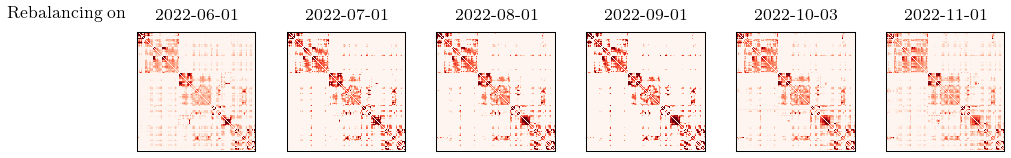

In [4]:
FIRST_WINDOW, N_WINDOWS = 40, 6  # rebalancings from 2022-06-01 to 2022-11-01

shown = ref["windows"][FIRST_WINDOW:FIRST_WINDOW + N_WINDOWS]
history = [
    AdmmIteration(
        terminates=w.info.terminates,
        start_train=w.info.train_start, end_train=w.info.train_end,
        start_test=w.info.test_start, end_test=w.info.test_end,
        duration_seconds=w.info.duration_seconds or 0.0,
        W=w.W, F=w.F, B=w.B,
    )
    for w in shown
]
cut_config = ref["strategies"][AllocationStrategy.ADMM_CUT].load_config().allocation
cut_alg = get_cut_alg(cut_type=cut_config.cut_type, splits_count=cut_config.splits_count)

plot_adjacency_from_history(
    history, ref["config"].admm.decay, ref["prices"], cut_alg,
    M=N_WINDOWS, save_path=ref["figures_dir"] / "adjacency_from_history.pdf",
)
plt.show()

## Figure 3: Learnt graph against correlation graph

Weight matrices of the learnt exposure similarity graph and of the correlation similarity graph for the S&P 500, reordered by GICS sector, in the calmest and most stressed rebalancing windows.

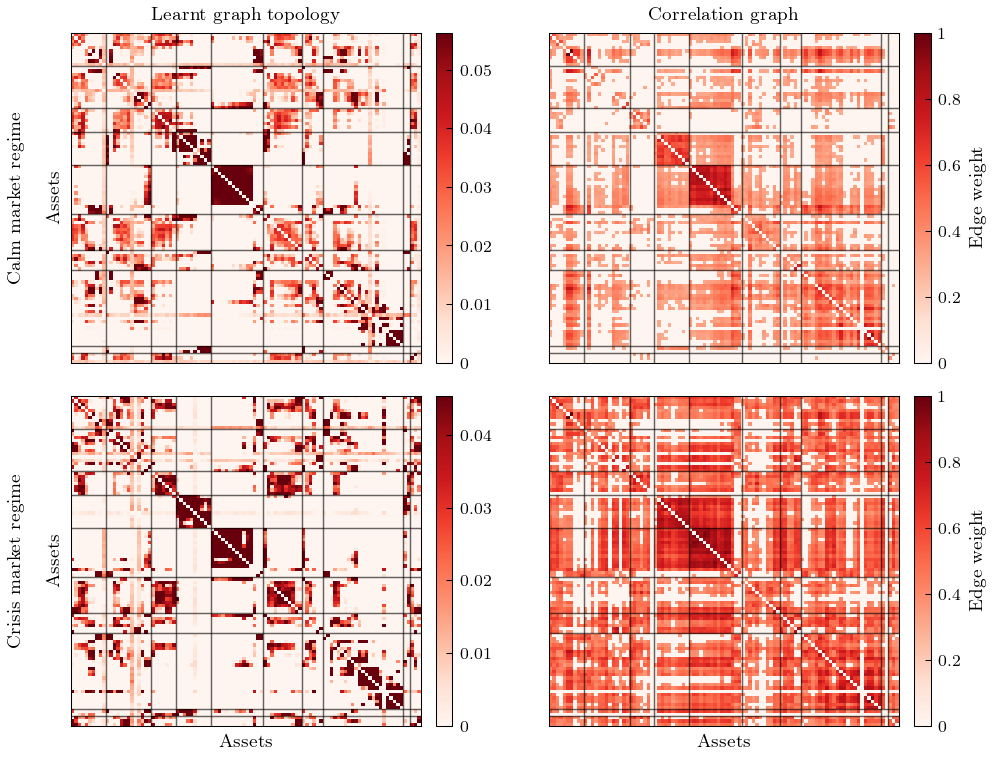

In [5]:
data_config = sp500["config"].data
metadata = pd.concat(
    [
        BloombergDataFetcher.get_metadata(data_config.data_dir / index.value / "metadata.csv", ticker_col="ticker")
        for index in data_config.indices
    ],
)
metadata = metadata[~metadata.index.duplicated()]
sectors = metadata.reindex(sp500["prices"].columns)["gics_sector_name"].fillna("Unknown")

plot_sector_comparison(
    sp500["windows"], sp500["prices"], sectors, sp500["vix"], sp500["regimes"],
    save_path=sp500["figures_dir"] / "adjacency_sector_boundaries.pdf",
)
plt.show()

## Figure 4: Conditioning of the representation-induced covariance

Condition number of the representation-induced covariance, Σ̂_R, against that of the sample covariance, Σ̂_S, over the backtest period.

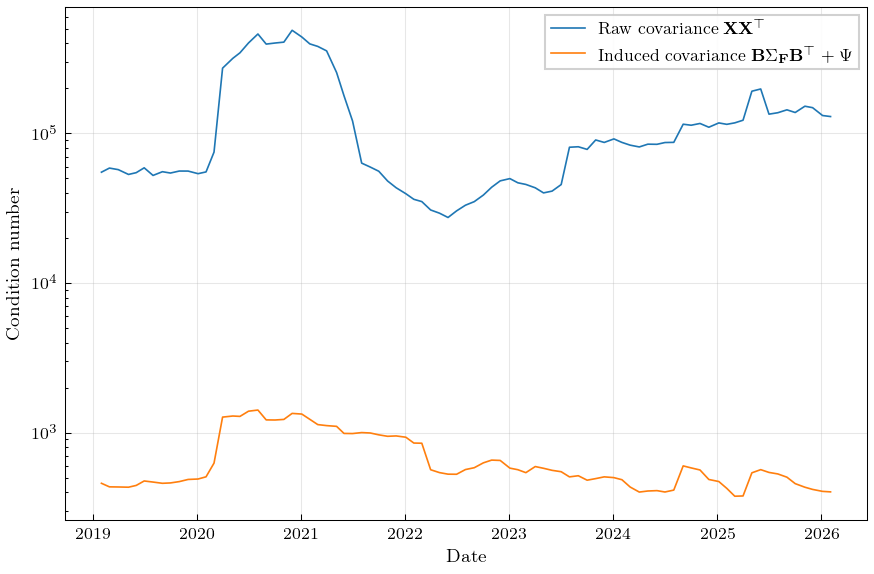

In [6]:
plot_cov_condition_evolution(
    ref["windows"], ref["prices"], ref["config"].admm.decay,
    save_path=ref["figures_dir"] / "cov_condition_evolution.pdf",
)
plt.show()

## Figure 5: Cumulative returns across market regimes

Cumulative returns of allocations on the learnt representation against the benchmarks, with CBOE VIX-defined regimes shaded.

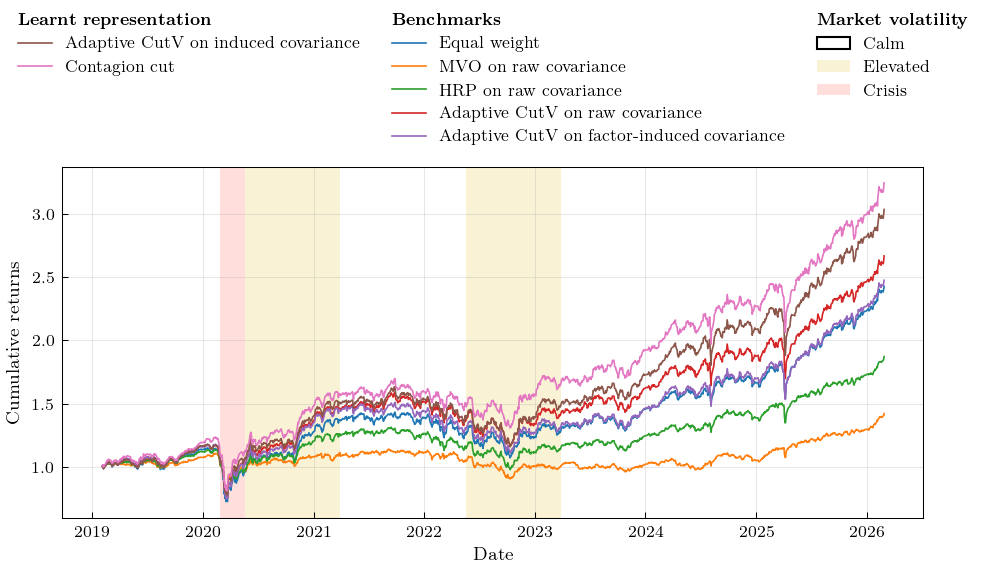

In [7]:
fig, ax = plt.subplots(figsize=(LatexSizes.DOUBLE_COLUMN, 4))
plot_regime_shaded_returns(
    ref["results"], ref["regimes"], start_test=ref["start_test"], ax=ax,
    save_path=ref["figures_dir"] / "regime_shaded_returns.pdf",
)
plt.show()

## Figure 6: Sharpe ratio within each market regime

Annualised Sharpe ratio of each portfolio within each VIX-derived volatility regime, computed over all trading days assigned to that regime.

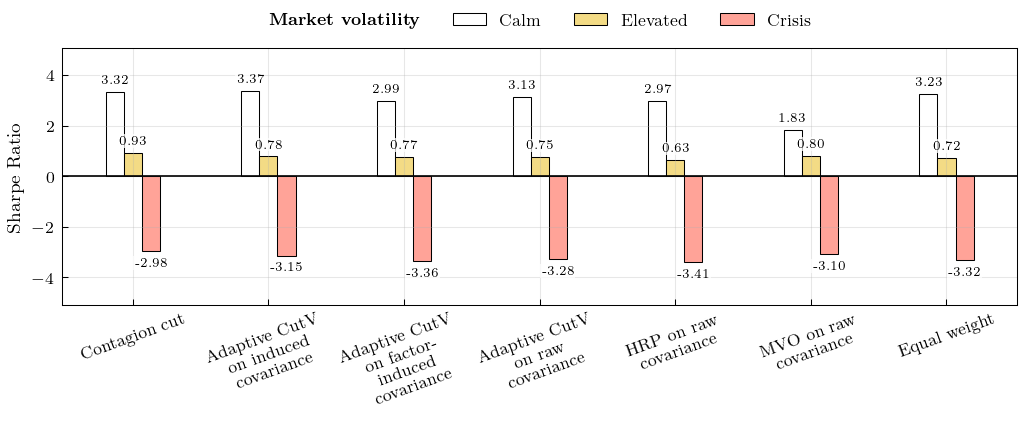

In [8]:
fig, ax = plt.subplots(figsize=(LatexSizes.DOUBLE_COLUMN, 3))
plot_performance_by_regime_bars(
    {alg.value: view for alg, view in reversed(list(ref["results"].items()))},
    ref["regimes"].loc[ref["start_test"]:], ref["rf_daily"], ref["market_returns"],
    ax=[ax], save_path=ref["figures_dir"] / "performance_by_regime_bars.pdf",
)
plt.show()